# Punto 1: Entrenamiento MLP - Clasificación

# Fase 1: Análisis y Exploración de Datos de Parkinson

En esta primera fase, vamos a:
1. Cargar y visualizar los datos.
2. Preprocesar las características numéricas (Scaling).
3. Dividir los datos en entrenamiento y validación/prueba.
4. Construir y entrenar un Perceptrón Multicapa (MLP) básico.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

I0000 00:00:1789331451.705504   27394 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1789331452.670967   27394 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1789331457.427943   27394 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


## 1. Carga y Exploración de los Datos

In [ ]:
# Asegúrate de que el archivo 'parkinsons.data' esté en el mismo directorio
df = pd.read_csv('../Data_entrenamiento/Punto_1/parkinsons.data')
display(df.head())
print("\nInformación del dataset:")
df.info()

SyntaxError: invalid syntax (1009586765.py, line 1)

### ¿Qué nos dice la radiografía de `df.info()`?

Imagina que esto es el resumen médico de nuestros datos. Nos acaba de revelar 4 cosas súper importantes:

1. **`195 entries` (Filas)**: Tenemos 195 muestras o grabaciones de voz en total.
2. **`24 columns` (Columnas)**: Tenemos 24 variables distintas por cada muestra.
3. **`195 non-null` (Datos completos)**: ¡Excelente noticia! Significa que no tenemos "huecos" ni datos vacíos en nuestra tabla. Si alguna dijera "190 non-null", sabríamos que nos faltan 5 datos ahí, pero aquí estamos al 100%.
4. **`Dtype` (Tipos de datos)**:
   - **`float64`** (22 columnas): Son números con decimales. Estas son todas las mediciones matemáticas de la voz (frecuencias, variaciones acústicas).
   - **`int64`** (1 columna): Es nuestra columna objetivo, el `status`. Como solo es `0` (Sano) o `1` (Parkinson), es un número entero. ¡Esto es lo que nuestra red va a aprender a predecir!
   - **`str` / `object`** (1 columna): Es la columna `name`, que solo tiene el código del paciente. Como no es un número matemático, no nos sirve para predecir, por lo que más adelante la borraremos.

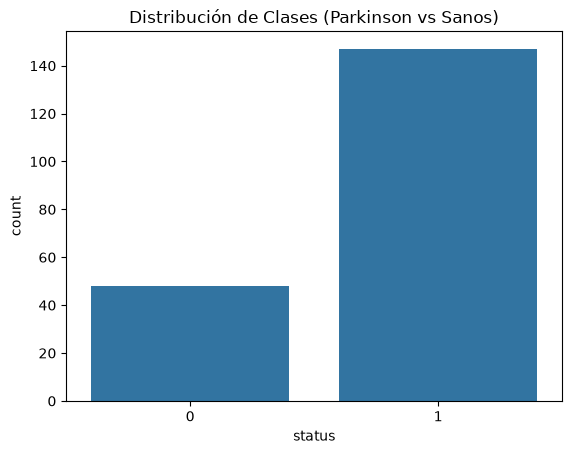

status
1    147
0     48
Name: count, dtype: int64


In [3]:
# Verificamos la distribución de la clase objetivo (status)
# 1 = Parkinson, 0 = Sano
sns.countplot(x='status', data=df)
plt.title('Distribución de Clases (Parkinson vs Sanos)')
plt.show()

print(df['status'].value_counts())

## 2. Preprocesamiento de Datos
La columna `name` no aporta valor predictivo por lo que la eliminaremos. Además, escalaremos las variables ya que las redes neuronales son sensibles a la escala de las entradas.

In [4]:
# Separar características (X) y objetivo (y)
X = df.drop(['name', 'status'], axis=1)
y = df['status']

# División de datos en Entrenamiento (80%) y Prueba (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f'Dimensión X_train: {X_train.shape}')
print(f'Dimensión X_test: {X_test.shape}')

Dimensión X_train: (156, 22)
Dimensión X_test: (39, 22)


In [5]:
# Escalamiento de datos (StandardScaler)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## 3. Modelo de Red Neuronal (MLP Superficial)

In [6]:
# Definición del modelo usando Keras
model = Sequential()

# Capa oculta con función de activación ReLU
# Usamos una arquitectura superficial: 1 capa oculta
model.add(Dense(32, input_dim=X_train_scaled.shape[1], activation='relu'))
model.add(Dropout(0.2)) # Prevención de sobreajuste

# Capa de salida con activación Sigmoid para clasificación binaria
model.add(Dense(1, activation='sigmoid'))

# Compilación del modelo
model.compile(optimizer='adam', 
              loss='binary_crossentropy', 
              metrics=['accuracy'])

model.summary()

/home/miguel-angel-ortiz/Documentos/Aprendizaje Avanzado/.venv/lib/python3.13/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
E0000 00:00:1789331458.843847   27394 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           736 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 769 (3.00 KB)

 Trainable params: 769 (3.00 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
# Entrenamiento del modelo
# Usamos el conjunto de prueba como datos de validación (validation_data) durante el entrenamiento
history = model.fit(X_train_scaled, y_train, 
                    epochs=50, 
                    batch_size=16, 
                    validation_data=(X_test_scaled, y_test), 
                    verbose=1)

Epoch 1/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.4808 - loss: 0.7245 - val_accuracy: 0.4872 - val_loss: 0.7392
Epoch 2/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5833 - loss: 0.6237 - val_accuracy: 0.5385 - val_loss: 0.6628
Epoch 3/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6731 - loss: 0.5689 - val_accuracy: 0.5641 - val_loss: 0.5993
Epoch 4/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7308 - loss: 0.5262 - val_accuracy: 0.6410 - val_loss: 0.5519
Epoch 5/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7372 - loss: 0.4986 - val_accuracy: 0.7179 - val_loss: 0.5090
Epoch 6/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8141 - loss: 0.4583 - val_accuracy: 0.7949 - val_loss: 0.4802
Epoch 7/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8013 - loss: 0.4430 - val_accuracy: 0.8462 - val_loss: 0.4546
Epoch 8/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8269 - loss: 0.4220 - val_accuracy: 0.8718 - val_loss

KeyboardInterrupt: 

## 4. Evaluación del Modelo

In [ ]:
# Graficar Loss y Accuracy
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Pérdida (Loss) vs Epochs')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Precisión (Accuracy) vs Epochs')
plt.legend()

plt.show()

In [ ]:
# Evaluación final y matriz de confusión
loss, accuracy = model.evaluate(X_test_scaled, y_test, verbose=0)
print(f"Precisión final en el conjunto de prueba: {accuracy:.4f}\n")

# Predicciones
y_pred_prob = model.predict(X_test_scaled)
y_pred = (y_pred_prob > 0.5).astype(int)

print("Matriz de Confusión:")
print(confusion_matrix(y_test, y_pred))
print("\nReporte de Clasificación:")
print(classification_report(y_test, y_pred))